# EfficientNet_02b: EfficientNet-B0, grouped split (34 species, unseen recordings), 3 seeds

**EfficientNet_02 recipe (2025), 3 seeds.** Same as EfficientNet_02 but repeated with seeds 42/43/44,
so later changes can be compared against the baseline's seed-to-seed spread (DL Lab 3).

Everything else is the 2025 recipe (see `EfficientNet_02.ipynb`). **Selection rule:** runs are compared on mean
*validation* macro-F1 over seeds 42/43/44; test metrics are recorded but not used for choosing.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src import config
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

GPU: NVIDIA GeForce RTX 5050 Laptop GPU


In [2]:
from src.EfficientNet.experiment import run_seeds
RUN = "EfficientNet_02b"
df = run_seeds(RUN, split="grouped", augment=False)
df

device=cuda | classes=34 | train=9502 val=2102 test=2057


Epoch 1/10 | train loss 1.2975 acc 75.09 | val loss 5.7980 acc 33.44 | lr 1.00e-03 | 118s


  saved best checkpoint -> efficientnet_02b_s42_best_01.pth


Epoch 2/10 | train loss 0.5018 acc 89.89 | val loss 4.3550 acc 37.49 | lr 1.00e-03 | 36s


  saved best checkpoint -> efficientnet_02b_s42_best_01.pth


Epoch 3/10 | train loss 0.2893 acc 94.24 | val loss 4.5755 acc 38.92 | lr 1.00e-03 | 36s


... (22 outputs left out)

  early stopping (no val-loss improvement for 3 epochs)


Training finished.


--> EfficientNet_02b_s44: val F1 0.278 acc 0.408 | best epoch 2/5


,run,seed,split,config,best_epoch,epochs_run,val_loss,val_acc,val_f1_macro,test_acc,test_f1_macro,minutes
0,EfficientNet_02b,42,grouped,"{""augment"": false}",2,5,4.3550,0.3749,0.2550,0.5921,0.4314,7.9
1,EfficientNet_02b,43,grouped,"{""augment"": false}",1,4,4.1228,0.3283,0.2207,0.5741,0.4185,2.6
2,EfficientNet_02b,44,grouped,"{""augment"": false}",2,5,4.0302,0.4077,0.2783,0.7103,0.4917,3.4


In [3]:
df[["val_f1_macro", "val_acc", "test_f1_macro", "test_acc", "best_epoch"]].agg(["mean", "std"]).round(3)

,val_f1_macro,val_acc,test_f1_macro,test_acc,best_epoch
mean,0.251,0.37,0.447,0.626,1.667
std,0.029,0.04,0.039,0.074,0.577


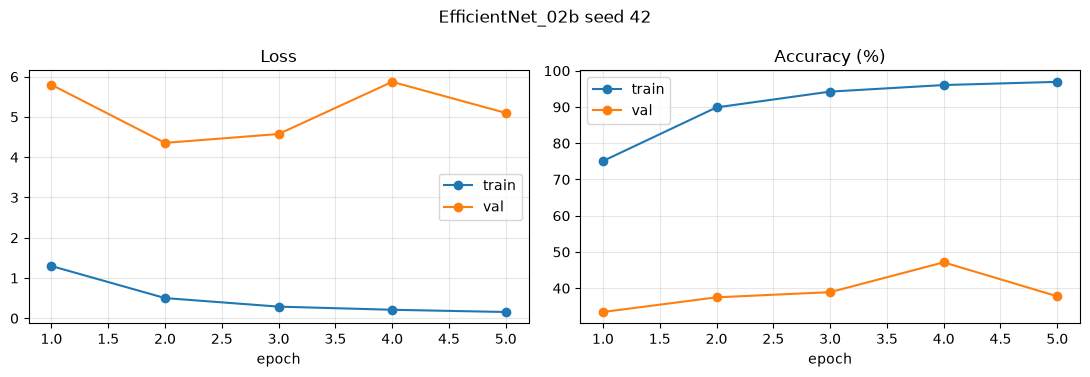

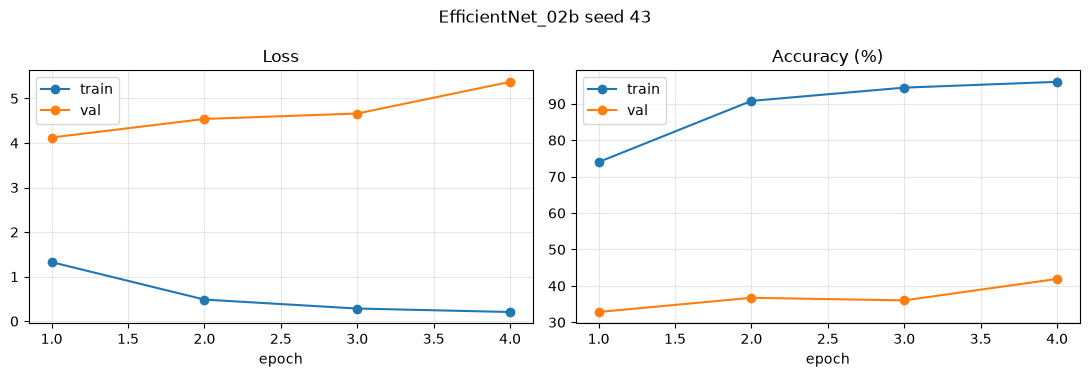

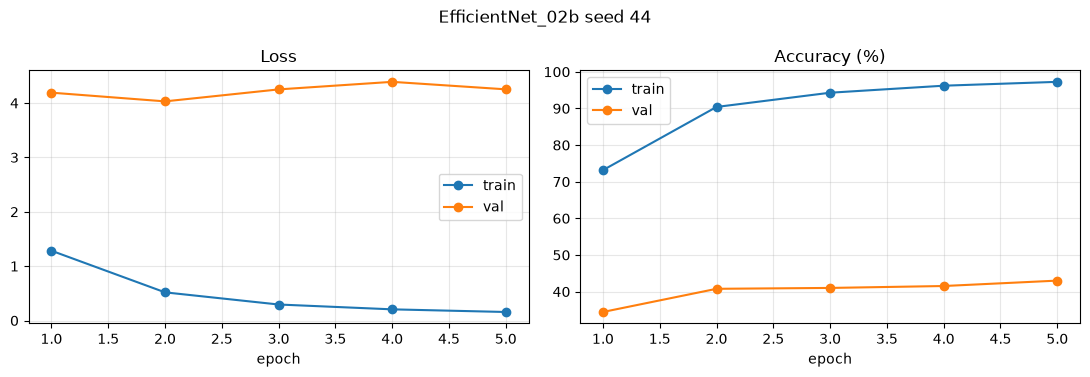

In [4]:
from src.plot_analysis import plot_learning_curves
import matplotlib.pyplot as plt
for s in df.seed:
    h = sorted(config.MODELS_OUTPUT.glob(f"{RUN.lower()}_s{s}_best_*_training_history.csv"))[-1]
    plot_learning_curves(h, f"{RUN} seed {s}", config.EVAL_DIR / f"learning_curves_{RUN}_s{s}.png"); plt.show()